In [1]:
import numpy as np
import os
import time
import scipy
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from matplotlib import cm

#Want to use version of Tensorflow > 2.0
print('Using Tensorflow version %s' % tf.__version__)


Using Tensorflow version 2.10.1


In [3]:
def writeFile(new_df, fileName):
    new_df.to_csv(fileName, sep=' ', index=False)#, header=None)

In [4]:
def find_intercept(x1,y1,x2,y2):
    # 2. Create continuous functions by interpolating the arrays
    f1 = scipy.interpolate.interp1d(x1, y1, kind='quadratic')
    f2 = scipy.interpolate.interp1d(x2, y2, kind='quadratic')

    # 3. Define the difference function (equals 0 at the intersection)
    def difference(x_val):
        return f1(x_val) - f2(x_val)
    
    # 4. Provide an initial guess near the crossing point and solve
    initial_guess = 0.5
    x_intercept = scipy.optimize.fsolve(difference, initial_guess)[0]
    y_intercept = f1(x_intercept)

    return x_intercept, y_intercept

In [4]:
#columns for input with all FFA parameters and output with only fixfield format particle data

fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]

fixfield_phase_space_headers =  ["x [m]", "y [m]", "z [m]", "ux []", "uy []", "uz []"]

fixfield_particle_info_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "Ptot [MeV/c]"]

FFA_sample_headers =  ["rmin [m]", "rmax [m]", "zmax [m]", "Cell opening angle [deg]", "r0 [m]", "k_val",
                        "C1", "lambda0",  "mag0 B0 [T]",  "mag0 cent_theta[deg]", "mag0 length_theta[deg]", 
                        "mag1 B0 [T]",  "mag1 cent_theta[deg]", "mag1 length_theta[deg]", "mag2 B0 [T]",  "mag2 cent_theta[deg]", "mag2 length_theta[deg]"]

ML_sample_headers =  ["rmin [m]", "rmax [m]", "zmax [m]", "Cell opening angle [deg]", "r0 [m]", "k_val",
                        "C1", "lambda0",  "mag0 B0 [T]",  "mag0 cent_theta[deg]", "mag0 length_theta[deg]", 
                        "mag1 B0 [T]",  "mag1 cent_theta[deg]", "mag1 length_theta[deg]", "mag2 B0 [T]",  "mag2 cent_theta[deg]", "mag2 length_theta[deg]", 
                        "m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]

print("input col num : "+str(len(ML_sample_headers))+", output col num : "+str(len(fixfield_headers)))
print(len(FFA_sample_headers))

input col num : 26, output col num : 9
17


In [5]:
#read generated sample data with pandas read_csv

FFA_ML_RNN_input = "ML_FFA_sample/ML_input_merged_rnn.dat"
FFA_ML_RNN_output_lst = ["ML_FFA_sample/ML_output_merged_1.dat", "ML_FFA_sample/ML_output_merged_2.dat"]
FFA_ML_RNN_FFA_lst = ["ML_FFA_sample/ML_FFA_merged_0.dat", "ML_FFA_sample/ML_FFA_merged_1.dat"]
FFA_num = len(FFA_ML_RNN_output_lst)

input_df = pd.DataFrame()
input_df = pd.read_csv(FFA_ML_RNN_input, sep = "\s+", skiprows=1, names=fixfield_headers) #input for ML contains all info of FFA magnets
input_phase_space_df = input_df[fixfield_phase_space_headers]
input_part_info_df = input_df[fixfield_particle_info_headers]
input_np_lst = input_df.to_numpy()
#input_part_info_np_lst = input_part_info_df.to_numpy()
input_phase_space_np_lst = input_phase_space_df.to_numpy()

all_data_df_lst = []#pd.concat([df1, df4], axis=1)
all_data_np_lst = []
output_df_lst = []
output_np_lst = []
output_phase_space_np_lst = []
output_part_info_np_lst = []
FFA_df_lst = []
FFA_np_lst = []
for i in range(0,FFA_num):
    output_df_lst.append(pd.DataFrame())
    FFA_df_lst.append(pd.DataFrame())
    all_data_df_lst.append(pd.DataFrame())
    
    output_df_lst[i] = pd.read_csv(FFA_ML_RNN_output_lst[i], sep = "\s+", skiprows=1, names=fixfield_headers) #output for ML contains only particle data in form of fixfield
    output_phase_space_df = output_df_lst[i][fixfield_phase_space_headers]
    #output_part_info_df = output_df_lst[i][fixfield_particle_info_headers]
    output_np_lst.append(output_df_lst[i].to_numpy())
    output_phase_space_np_lst.append(output_phase_space_df.to_numpy())
    #output_part_info_np_lst.append(output_part_info_df.to_numpy())

    FFA_df_lst[i] = pd.read_csv(FFA_ML_RNN_FFA_lst[i], sep = "\s+", skiprows=1, names=FFA_sample_headers)
    FFA_np_lst.append(FFA_df_lst[i].to_numpy())

all_data_df_lst[0] = pd.concat([input_df, FFA_df_lst[0]], axis=1)
all_data_df_lst[1] = pd.concat([output_df_lst[0], FFA_df_lst[1]], axis=1)

for i in range(0,FFA_num):
    all_data_np_lst.append(all_data_df_lst[i].to_numpy())

output_lost_lst = np.ones(len(input_df["x [m]"])) #list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

print("number of particles : "+str(len(input_df["x [m]"])))

#============================================================================================================
#put the read data into np array

total_part_num = len(input_df["x [m]"])
sample_part_num = int(total_part_num/2)#assgin half of sample for train and other half for validation
input_col_num = len(ML_sample_headers)
input_para_col_num = len(FFA_sample_headers)
input_phase_space_col_num = len(fixfield_phase_space_headers)
input_part_info_col_num = len(fixfield_particle_info_headers)

FFA_parameter_len = len(FFA_sample_headers)
output_col_num = len(fixfield_phase_space_headers)

input_train_RNN = np.zeros(sample_part_num*FFA_num*input_col_num).reshape((sample_part_num,FFA_num,input_col_num)) #training data
input_FFA_para_train_RNN = np.zeros(sample_part_num*FFA_num*input_para_col_num).reshape((sample_part_num,FFA_num,input_para_col_num)) #FFA para
input_part_info_train_RNN = np.zeros(sample_part_num*input_part_info_col_num).reshape((sample_part_num,input_part_info_col_num))#part mass, charge, momentum
input_phase_space_train_RNN = np.zeros(sample_part_num*FFA_num*input_phase_space_col_num).reshape((sample_part_num,FFA_num,input_phase_space_col_num)) #training data
output_train_RNN = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num))
output_lost_train_RNN = np.ones(sample_part_num)#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

input_val_RNN = np.zeros(sample_part_num*FFA_num*input_col_num).reshape((sample_part_num,FFA_num,input_col_num)) #validation data
input_FFA_para_val_RNN = np.zeros(sample_part_num*FFA_num*input_para_col_num).reshape((sample_part_num,FFA_num,input_para_col_num)) #training data
input_part_info_val_RNN = np.zeros(sample_part_num*input_part_info_col_num).reshape((sample_part_num,input_part_info_col_num))
input_phase_space_val_RNN = np.zeros(sample_part_num*FFA_num*input_phase_space_col_num).reshape((sample_part_num,FFA_num,input_phase_space_col_num)) #training data
output_val_RNN = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num))
output_lost_val_RNN = np.ones(sample_part_num)#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

lost_count_train = 0
lost_count_val = 0

for i in range(0,sample_part_num):
    for j in range(0,FFA_num):

        input_train_RNN[i][j] = all_data_np_lst[j][2*i]
        input_val_RNN[i][j] = all_data_np_lst[j][2*i+1]

        input_FFA_para_train_RNN[i][j] = FFA_np_lst[j][2*i]
        input_FFA_para_val_RNN[i][j] = FFA_np_lst[j][2*i+1]

        if j==0:

            input_phase_space_train_RNN[i][j] = input_phase_space_np_lst[2*i]
            input_phase_space_val_RNN[i][j] = input_phase_space_np_lst[2*i+1]

        else:
            input_phase_space_train_RNN[i][j] = output_phase_space_np_lst[j-1][2*i]
            input_phase_space_val_RNN[i][j] = output_phase_space_np_lst[j-1][2*i+1]

    
    output_train_RNN[i] = output_phase_space_np_lst[-1][2*i]
    output_val_RNN[i] = output_phase_space_np_lst[-1][2*i+1]

    if (output_train_RNN[i][3]+output_train_RNN[i][4]+output_train_RNN[i][5])<1e-6:#lost particles have 0 phase space val. So sum of ux,uy,uz is 0 -> lost
        output_lost_train_RNN[i] = 0#if particle is lost assign 0
        lost_count_train = lost_count_train + 1

    if (output_val_RNN[i][3]+output_val_RNN[i][4]+output_val_RNN[i][5])<1e-6:
        output_lost_val_RNN[i] = 0
        lost_count_val = lost_count_val + 1



print("input_train")
print(input_train_RNN)
print(input_train_RNN.shape)
print("output_train")
print(output_train_RNN)
print(output_train_RNN.shape)
print(output_val_RNN.shape)
print("output_lost_train")
print(output_lost_train_RNN)
print("lost_count_train : "+str(lost_count_train)+", lost_count_val : "+str(lost_count_val))
print(output_np_lst[0][4])
print("train particle num : "+str(len(input_train_RNN))+", val particle num : "+str(len(input_val_RNN))
      +", input column : "+str(len(input_train_RNN[0]))+",  output column : "+str(len(output_train_RNN[0])))

number of particles : 46875
input_train
[[[ 1.01430586e+02  1.00000000e+00 -2.93373120e-02 ... -1.98623772e+00
    1.14412869e+01  1.50963360e+00]
  [ 1.01430600e+02  1.00000000e+00 -6.43452500e-02 ... -2.08257762e+00
    1.11522671e+01  1.44219567e+00]]

 [[ 1.02796525e+02  1.00000000e+00 -6.99380017e-02 ... -1.98623772e+00
    1.14412869e+01  1.50963360e+00]
  [ 1.02796500e+02  1.00000000e+00 -4.88191600e-02 ... -2.08257762e+00
    1.11522671e+01  1.44219567e+00]]

 [[ 1.02219651e+02  1.00000000e+00  1.95267718e-01 ... -1.98623772e+00
    1.14412869e+01  1.50963360e+00]
  [ 1.02219700e+02  1.00000000e+00 -2.43454200e-01 ... -2.08257762e+00
    1.11522671e+01  1.44219567e+00]]

 ...

 [[ 2.03498441e+02  1.00000000e+00  1.19764948e-01 ... -2.09100739e+00
    1.11269778e+01  1.43629483e+00]
  [ 2.03498441e+02  1.00000000e+00  0.00000000e+00 ... -2.02050971e+00
    1.13384709e+01  1.48564321e+00]]

 [[ 2.00923915e+02  1.00000000e+00  2.52569611e-02 ... -2.09100739e+00
    1.11269778e+01 

[]

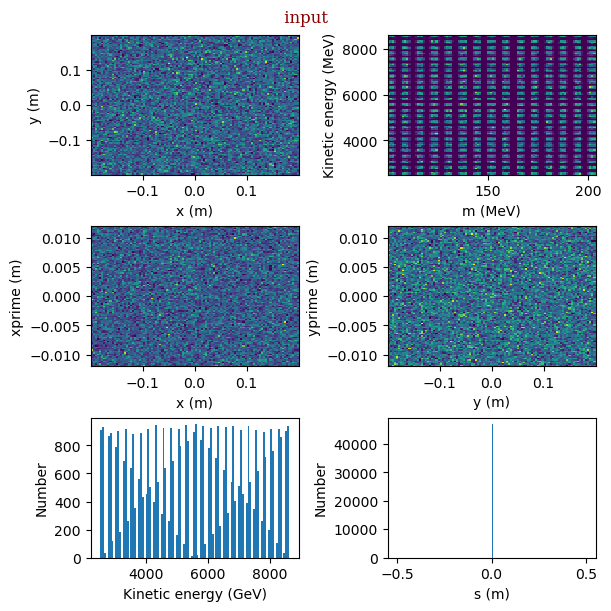

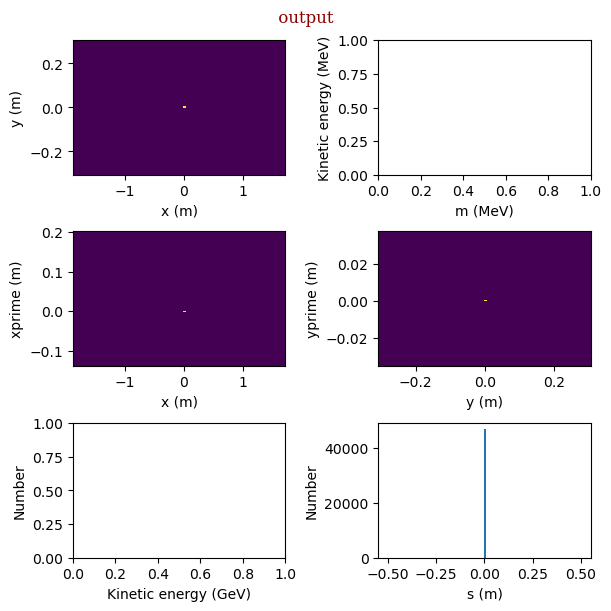

In [6]:
logE = False
font = {'family': 'serif', \
        'color':  'darkred' \
        }

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " input "

fig.suptitle(Ttl, fontdict=font)

#axs[0, 0].set_title('x,y')
axs[0, 0].hist2d(input_df["x [m]"].to_numpy(), input_df["z [m]"].to_numpy(), bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

#axs[0, 1].set_title('delta')

axs[0, 1].hist2d(input_df["m0 [MeV*c^-2]"].to_numpy(), input_df["Ptot [MeV/c]"].to_numpy(), bins=100)#2d hist of energy and r
axs[0, 1].set_xlabel('m (MeV)')
axs[0, 1].set_ylabel('Kinetic energy (MeV)')

#axs[1, 0].set_title('x, xprime')
axs[1, 0].hist2d(input_df["x [m]"].to_numpy(), input_df["ux []"].to_numpy(), bins=100)
axs[1, 0].set_xlabel('x (m)')
axs[1, 0].set_ylabel('xprime (m)')

#axs[1, 1].set_title('y, yprime')
axs[1, 1].hist2d(input_df["z [m]"].to_numpy(), input_df["uz []"].to_numpy(), bins=100)
axs[1, 1].set_xlabel('y (m)')
axs[1, 1].set_ylabel('yprime (m)')

axs[2, 0].hist(input_df["Ptot [MeV/c]"].to_numpy(), 100)
axs[2, 0].set_yscale('linear')
if logE:
    axs[2, 0].set_yscale('log')
axs[2, 0].set_xlabel('Kinetic energy (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].hist(input_df["y [m]"].to_numpy(), 100)
axs[2, 1].set_yscale('linear')
if logE:
    axs[2, 1].set_yscale('log')
axs[2, 1].set_xlabel('s (m)')
axs[2, 1].set_ylabel('Number')

plt.plot()

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " output "

fig.suptitle(Ttl, fontdict=font)

#axs[0, 0].set_title('x,y')
axs[0, 0].hist2d(output_df_lst[0]["x [m]"].to_numpy(), output_df_lst[0]["z [m]"].to_numpy(), bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

#axs[0, 1].set_title('delta')

#axs[0, 1].hist2d(output_df["m0 [MeV*c^-2]"].to_numpy(), output_df["Ptot [MeV/c]"].to_numpy(), bins=100)#2d hist of energy and r
axs[0, 1].set_xlabel('m (MeV)')
axs[0, 1].set_ylabel('Kinetic energy (MeV)')

#axs[1, 0].set_title('x, xprime')
axs[1, 0].hist2d(output_df_lst[0]["x [m]"].to_numpy(), output_df_lst[0]["ux []"].to_numpy(), bins=100)
axs[1, 0].set_xlabel('x (m)')
axs[1, 0].set_ylabel('xprime (m)')

#axs[1, 1].set_title('y, yprime')
axs[1, 1].hist2d(output_df_lst[0]["z [m]"].to_numpy(), output_df_lst[0]["uz []"].to_numpy(), bins=100)
axs[1, 1].set_xlabel('y (m)')
axs[1, 1].set_ylabel('yprime (m)')

#axs[2, 0].hist(output_df["Ptot [MeV/c]"].to_numpy(), 100)
axs[2, 0].set_yscale('linear')
if logE:
    axs[2, 0].set_yscale('log')
axs[2, 0].set_xlabel('Kinetic energy (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].hist(output_df_lst[0]["y [m]"].to_numpy(), 100)
axs[2, 1].set_yscale('linear')
if logE:
    axs[2, 1].set_yscale('log')
axs[2, 1].set_xlabel('s (m)')
axs[2, 1].set_ylabel('Number')

plt.plot()

In [7]:
#create model
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(None, input_col_num)),
    tf.keras.layers.BatchNormalization(),
    #tf.keras.layers.LayerNormalization(),
    tf.keras.layers.SimpleRNN(64, return_sequences=True),#, input_shape=[None, input_col_num]
    tf.keras.layers.SimpleRNN(64),
    tf.keras.layers.Dense(192, activation='tanh'),
    tf.keras.layers.Dense(output_col_num)#, activation='tanh')
])

In [8]:
#compile the model
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  KLDivergence  Poisson
loss_fn = tf.keras.losses.MeanSquaredError()

model.compile(optimizer='adam',
              loss=loss_fn,#,#,huber_loss
              metrics=['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 batch_normalization (BatchN  (None, None, 26)         104       
 ormalization)                                                   
                                                                 
 simple_rnn (SimpleRNN)      (None, None, 64)          5824      
                                                                 
 simple_rnn_1 (SimpleRNN)    (None, 64)                8256      
                                                                 
 dense (Dense)               (None, 192)               12480     
                                                                 
 dense_1 (Dense)             (None, 6)                 1158      
                                                                 
Total params: 27,822
Trainable params: 27,770
Non-trainable params: 52
___________________________________________________

In [9]:
print(input_train_RNN.shape)
print(input_val_RNN.shape)
print(output_train_RNN.shape)
print(output_val_RNN.shape)
print(len(input_train_RNN))

(23437, 2, 26)
(23437, 2, 26)
(23437, 6)
(23437, 6)
23437


In [10]:
#train the model
num_epochs = 250
#Not worried about memory or local minima
batchSize = len(input_train_RNN)

#Train on data
history = model.fit(input_train_RNN, output_train_RNN,
          validation_data=(input_val_RNN, output_val_RNN),
          batch_size=batchSize,
          epochs=num_epochs)

full_model_filename = 'FFA_simple_RNN_model'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 1/250
1/1 [==============================] - 2s 2s/step - loss: 0.3115 - accuracy: 0.0767 - val_loss: 0.3131 - val_accuracy: 0.4348
Epoch 2/250
1/1 [==============================] - 0s 28ms/step - loss: 0.1352 - accuracy: 0.1216 - val_loss: 0.3581 - val_accuracy: 0.3941
Epoch 3/250
1/1 [==============================] - 0s 25ms/step - loss: 0.0754 - accuracy: 0.2252 - val_loss: 0.3723 - val_accuracy: 0.3256
Epoch 4/250
1/1 [==============================] - 0s 26ms/step - loss: 0.0728 - accuracy: 0.2491 - val_loss: 0.3824 - val_accuracy: 0.3606
Epoch 5/250
1/1 [==============================] - 0s 28ms/step - loss: 0.0796 - accuracy: 0.2765 - val_loss: 0.3784 - val_accuracy: 0.3441
Epoch 6/250
1/1 [==============================] - 0s 29ms/step - loss: 0.0806 - accuracy: 0.3425 - val_loss: 0.3624 - val_accuracy: 0.2865
Epoch 7/250
1/1 [==============================] - 0s 28ms/step - loss: 0.0767 - accuracy: 0.3741 - val_loss: 0.3381 - val_accuracy: 0.2141
Epoch 8/250
1/1 [=====

733/733 - 1s - loss: 0.1134 - accuracy: 0.1034 - 1s/epoch - 2ms/step


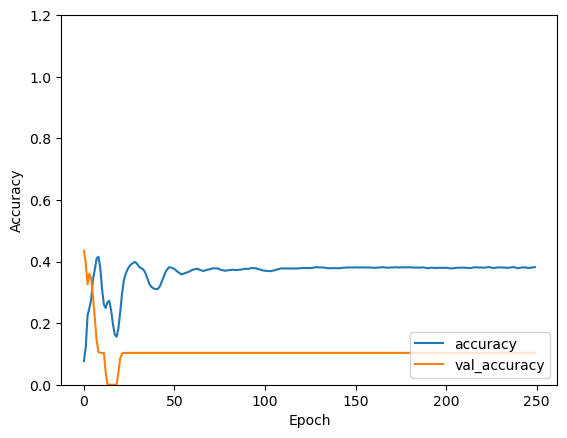

In [11]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

val_loss, val_acc = model.evaluate(input_val_RNN,  output_val_RNN, verbose=2)

733/733 - 1s - loss: 0.1134 - accuracy: 0.1034 - 1s/epoch - 2ms/step


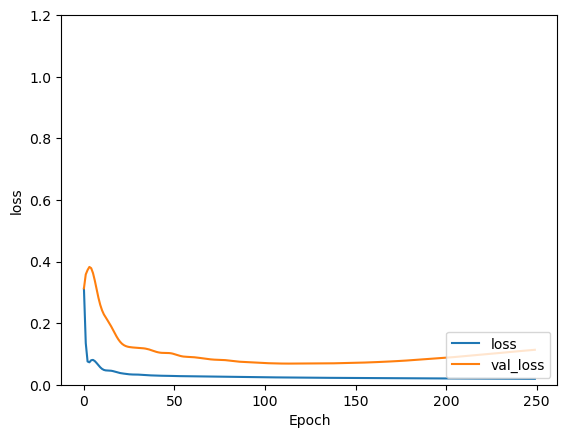

In [12]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

val_loss, val_acc = model.evaluate(input_val_RNN,  output_val_RNN, verbose=2)

In [13]:
output_prediction = model.predict(input_val_RNN)

ML_result_df = pd.DataFrame(output_prediction, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_simple_RNN_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

733/733 [==============================] - 1s 1ms/step
writing to file : ML_FFA_sample/FFA_ML_simple_RNN_result.dat


In [14]:
start_index = 0
end_index = 3000
print(output_val_RNN[start_index:end_index])
print(output_prediction[start_index:end_index])

[[-1.383964    0.          0.04965096 -0.1010709   0.9948715   0.00391276]
 [-1.4321      0.         -0.09819983 -0.09356459  0.9955038  -0.01476015]
 [-1.120373    0.          0.01231477 -0.0958046   0.9950476   0.02648986]
 ...
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]]
[[-0.20709008  0.08329634  0.30209923  0.01167692  0.78577816 -0.15250817]
 [-0.16430718  0.06125115  0.30996984  0.01791881  0.78322417 -0.16539675]
 [-0.2151742   0.1090977   0.30577406 -0.00391239  0.7884831  -0.14741796]
 ...
 [-0.21776852  0.08418736  0.3143754  -0.03619803  0.53383064 -0.07354759]
 [-0.15493584  0.06913547  0.33597237 -0.04154173  0.5436881  -0.07330745]
 [-0.22742175  0.07039661  0.31173557 -0.03928714  0.53311855 -0.06789749]]


23437
pred data
[[-0.20709008  0.08329634  0.30209923  0.01167692  0.78577816 -0.15250817]
 [-0.16430718  0.06125115  0.30996984  0.01791881  0.78322417 -0.16539675]
 [-0.2151742   0.1090977   0.30577406 -0.00391239  0.7884831  -0.14741796]
 ...
 [-0.06546435  0.04871543  0.28784877 -0.11130702  0.68834794 -0.12648931]
 [-0.04662874  0.04650903  0.29070097 -0.11465497  0.6850879  -0.12904   ]
 [-0.08652083  0.05560593  0.26872563 -0.11684991  0.66722584 -0.1240996 ]]
val data
[[-1.383964    0.          0.04965096 -0.1010709   0.9948715   0.00391276]
 [-1.4321      0.         -0.09819983 -0.09356459  0.9955038  -0.01476015]
 [-1.120373    0.          0.01231477 -0.0958046   0.9950476   0.02648986]
 ...
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]]


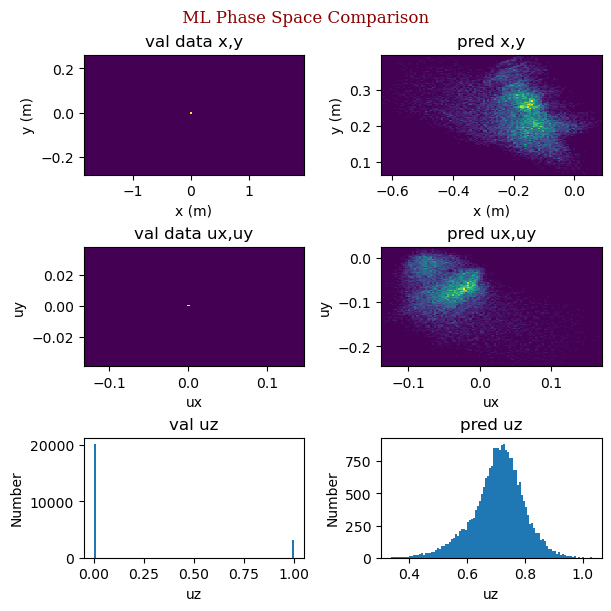

In [15]:
print(len(output_prediction))
print("pred data")
print(output_prediction)
print("val data")
print(output_val_RNN)

unpack_output_val = output_val_RNN

part_num = len(output_prediction)
#val_survive_index = []

#print("val surving particle num : "+str(len(val_survive_index)))
#+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")


fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(output_prediction[:,0], output_prediction[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(output_prediction[:,3], output_prediction[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('uz')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(output_prediction[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [16]:
#=================================================================================
#Advanced architecture with same data as above
#=================================================================================

In [17]:
fixfield_part_info_input = tf.keras.Input(shape=(input_part_info_col_num,),name="fixfield_part_info_input")

fixfield_phase_space_input = tf.keras.Input(shape=(None, input_phase_space_col_num),name="fixfield_phase_space_input")

FFA_parameters = tf.keras.Input(shape=(None, FFA_parameter_len),name="ffa_parameters")

part_info = tf.keras.layers.BatchNormalization()(fixfield_part_info_input)
part_info = tf.keras.layers.Dense(64, activation="tanh")(part_info)# phase space input
part_info = tf.keras.layers.Dense(64)(part_info)

phase_space = tf.keras.layers.BatchNormalization()(fixfield_phase_space_input)
phase_space = tf.keras.layers.Dense(64, activation="tanh")(phase_space)
phase_space = tf.keras.layers.Dense(64)(phase_space)

FFA_para = tf.keras.layers.BatchNormalization()(FFA_parameters)
FFA_para = tf.keras.layers.Dense(64, activation="tanh")(FFA_para)
FFA_para = tf.keras.layers.Dense(64)(FFA_para)

combined_RNN = tf.keras.layers.Concatenate()([phase_space, FFA_para])
combined_RNN = tf.keras.layers.SimpleRNN(64, return_sequences=True)(combined_RNN)#, input_shape=[None, input_col_num]
combined_RNN = tf.keras.layers.SimpleRNN(64)(combined_RNN)

combined_all = tf.keras.layers.Concatenate()([combined_RNN, part_info])
combined_all = tf.keras.layers.Dense(128, activation="tanh")(combined_all)

phase_space_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_output")(combined_all)# phase space output
survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(combined_all)# Binary classification

model_RNN_sep_in_out = tf.keras.models.Model(
    inputs=[fixfield_part_info_input, fixfield_phase_space_input, FFA_parameters],
    outputs=[phase_space_output,survival_output]
)

In [18]:
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  Huber()  KLDivergence  Poisson

model_RNN_sep_in_out.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss={
        "phase_space_output": tf.keras.losses.Huber(),
        "survival_output": tf.keras.losses.BinaryCrossentropy()
    },

    loss_weights={
        "phase_space_output": 1.0,
        "survival_output": 0.3
    },

    weighted_metrics={
        "phase_space_output": ["accuracy"],#mae
        "survival_output": ["accuracy"]
    }
)

model_RNN_sep_in_out.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 fixfield_phase_space_input (In  [(None, None, 6)]   0           []                               
 putLayer)                                                                                        
                                                                                                  
 ffa_parameters (InputLayer)    [(None, None, 17)]   0           []                               
                                                                                                  
 batch_normalization_2 (BatchNo  (None, None, 6)     24          ['fixfield_phase_space_input[0][0
 rmalization)                                                    ]']                              
                                                                                              

In [19]:
#train the model
num_epochs = 750
#Not worried about memory or local minima
batchSize = len(input_train_RNN)

#Train on data
history = model_RNN_sep_in_out.fit(
    x={
        "fixfield_part_info_input": input_part_info_train_RNN,
        "fixfield_phase_space_input": input_phase_space_train_RNN,
        "ffa_parameters": input_FFA_para_train_RNN
    },

    y={
        "phase_space_output": output_train_RNN,
        "survival_output": output_lost_train_RNN
    },

    sample_weight={
        "phase_space_output": output_lost_train_RNN,
        "survival_output": np.ones(sample_part_num)
    },

    validation_data=({
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    },

    {
        "phase_space_output": output_val_RNN,
        "survival_output": output_lost_val_RNN
    }#,

    #{"phase_space_output": output_lost_val,"survival_output": np.ones(sample_part_num)}#weight for validation data
    ),


    epochs=num_epochs,
    batch_size=batchSize
)

full_model_filename = 'model_RNN_sep_in_out'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model_RNN_sep_in_out.save(model_filename)

Epoch 1/750
1/1 [==============================] - 2s 2s/step - loss: 0.2493 - phase_space_output_loss: 0.0242 - survival_output_loss: 0.7503 - phase_space_output_accuracy: 0.1595 - survival_output_accuracy: 0.4417 - val_loss: 0.4205 - val_phase_space_output_loss: 0.0738 - val_survival_output_loss: 1.1555 - val_phase_space_output_accuracy: 0.0000e+00 - val_survival_output_accuracy: 0.1355
Epoch 2/750
1/1 [==============================] - 0s 84ms/step - loss: 0.2014 - phase_space_output_loss: 0.0192 - survival_output_loss: 0.6074 - phase_space_output_accuracy: 0.4270 - survival_output_accuracy: 0.8082 - val_loss: 0.4230 - val_phase_space_output_loss: 0.0706 - val_survival_output_loss: 1.1748 - val_phase_space_output_accuracy: 0.0000e+00 - val_survival_output_accuracy: 0.1355
Epoch 3/750
1/1 [==============================] - 0s 89ms/step - loss: 0.1679 - phase_space_output_loss: 0.0156 - survival_output_loss: 0.5077 - phase_space_output_accuracy: 0.6485 - survival_output_accuracy: 0.86

733/733 - 3s - loss: 0.0386 - phase_space_output_loss: 3.9806e-04 - survival_output_loss: 0.1275 - phase_space_output_accuracy: 0.9515 - survival_output_accuracy: 0.9459 - 3s/epoch - 5ms/step


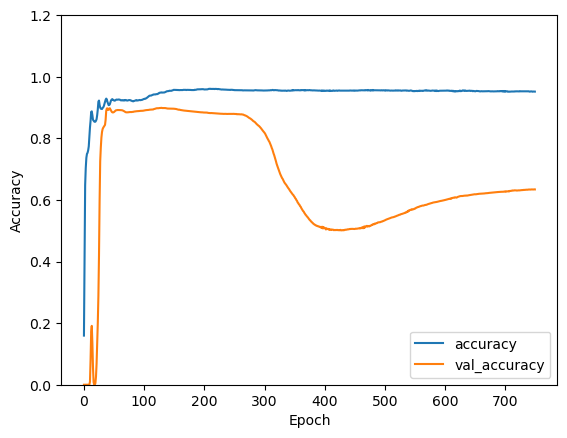

In [20]:
plt.plot(history.history['phase_space_output_accuracy'], label='accuracy')
plt.plot(history.history['val_phase_space_output_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

#val_loss_phase_space, val_loss_lost_part, val_acc_phase_space,  val_acc_lost_part
results = model_RNN_sep_in_out.evaluate(x={
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    },
    y={
        "phase_space_output": output_val_RNN,
        "survival_output": output_lost_val_RNN
    },
   sample_weight={
        "phase_space_output": output_lost_val_RNN,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

733/733 - 3s - loss: 0.0386 - phase_space_output_loss: 3.9806e-04 - survival_output_loss: 0.1275 - phase_space_output_accuracy: 0.9515 - survival_output_accuracy: 0.9459 - 3s/epoch - 4ms/step


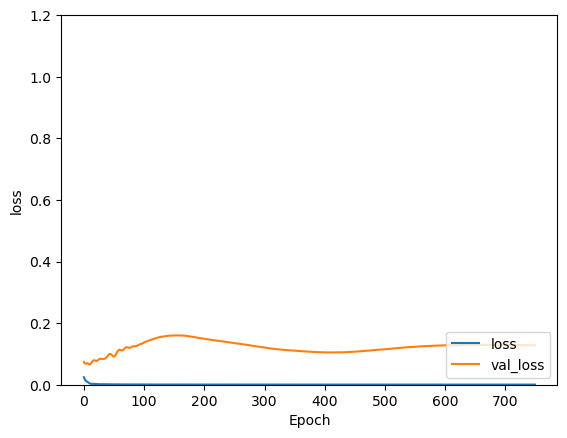

In [21]:
plt.plot(history.history['phase_space_output_loss'], label='loss')
plt.plot(history.history['val_phase_space_output_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

results = model_RNN_sep_in_out.evaluate(x={
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    },
    y={
        "phase_space_output": output_val_RNN,
        "survival_output": output_lost_val_RNN
    },
   sample_weight={
        "phase_space_output": output_lost_val_RNN,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

In [22]:
output_sep_in_out_prediction = model_RNN_sep_in_out.predict({
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    })
phase_space_pred = output_sep_in_out_prediction[0]
part_lost_pred = output_sep_in_out_prediction[1].squeeze()


ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_sep_in_out_RNN_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

733/733 [==============================] - 2s 3ms/step
writing to file : ML_FFA_sample/FFA_ML_sep_in_out_RNN_result.dat


pred data
[2.14712168e-06 4.41366637e-07 1.07184906e-06 6.38707434e-07
 2.86138771e-07 3.31316357e-07 7.52364429e-07 2.40628054e-07
 7.23685332e-07 2.23663642e-06 5.84798840e-07 1.25125769e-06
 4.07752736e-07 7.35268316e-07 2.89426936e-07 2.14921045e-07
 1.93521288e-07 1.23936729e-06 4.29437790e-07 6.02617050e-08
 1.16926969e-06 1.73396444e-07 8.07491006e-07 2.70968085e-05
 2.58044253e-07 1.13777354e-07 2.77785460e-07 1.91227130e-07
 7.87652898e-05 1.40849650e-07]
val data
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
Within 23437 particles 13.551222426078425 % survival rate
Threshold value to have correct survival rate : 0.4467192084046735 est_sruvive_rate 0.13551222426078427
correct survival rate at same_survive : 0.7946670901890415 lost rate 0.967613704380765


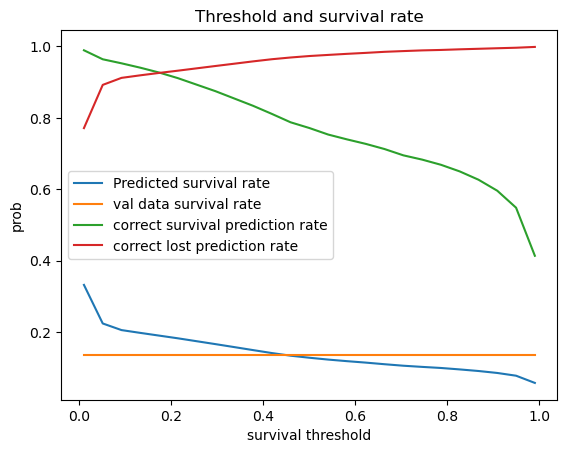

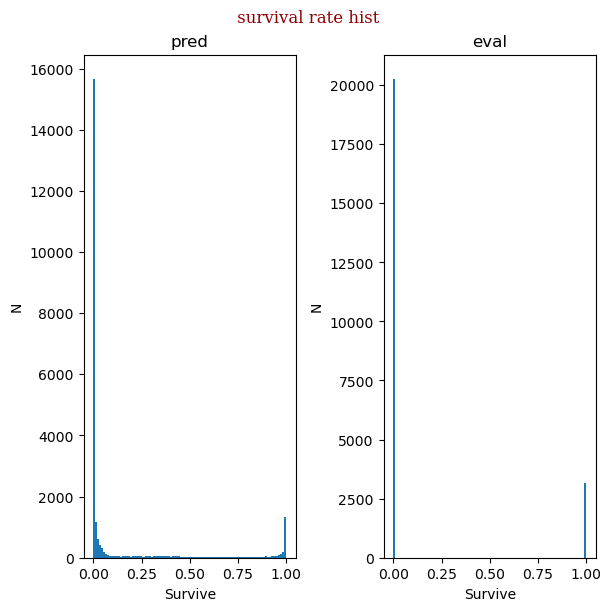

In [23]:
start_index = 270
end_index = 300
print("pred data")
print(part_lost_pred[start_index:end_index])
print("val data")
print(output_lost_val_RNN[start_index:end_index])

#calc total survival prob
thresh_num = 25
survive_thresh_lst = np.linspace(0.01,0.99,thresh_num)
pred_prob_lst = np.zeros(thresh_num)
val_prob_lst = np.zeros(thresh_num)
correct_sur_prob_lst = np.zeros(thresh_num)
correct_lost_prob_lst = np.zeros(thresh_num)

for thresh_index in range(0, thresh_num):
    survive_thresh = survive_thresh_lst[thresh_index]
    pred_prob = 0
    val_prob = 0
    correct_sur_prob = 0
    correct_lost_prob = 0
    part_num = len(part_lost_pred)
    for i in range(0, part_num):
        if part_lost_pred[i]>survive_thresh:
            pred_prob = pred_prob + 1
    
        if output_lost_val_RNN[i]>survive_thresh:
            val_prob = val_prob + 1
            if part_lost_pred[i]>survive_thresh:
                correct_sur_prob = correct_sur_prob + 1 #add when both val data and pred is surviving
        else:
            if part_lost_pred[i]<survive_thresh:
                correct_lost_prob = correct_lost_prob + 1 #add when both val data and pred is lost
    
    correct_sur_prob = correct_sur_prob/val_prob #devide by val data surviving particle number
    correct_lost_prob = correct_lost_prob/(part_num-val_prob) #devide by val data lost particle number
    pred_prob = pred_prob/part_num
    val_prob = val_prob/part_num

    correct_sur_prob_lst[thresh_index] = correct_sur_prob
    correct_lost_prob_lst[thresh_index] = correct_lost_prob
    pred_prob_lst[thresh_index] = pred_prob
    val_prob_lst[thresh_index] = val_prob

    #print("Threshold value for survival : "+str(survive_thresh))
    #print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate and "+str(pred_prob*100)+" % survival rate from prediction")
    #print(str(correct_sur_prob*100)+" % correct survival prediction and "+str(correct_lost_prob*100)+" % correct lost prediction")


same_survive_thresh, est_sruvive_rate = find_intercept(survive_thresh_lst, val_prob_lst, survive_thresh_lst, pred_prob_lst)
#same_survive_thresh,est_sruvive_rate = 0.4,0.13

print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate")
print("Threshold value to have correct survival rate : "+str(same_survive_thresh)+" est_sruvive_rate "+str(est_sruvive_rate))

f_correct_sur_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_sur_prob_lst, kind='linear')
f_correct_lost_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_lost_prob_lst, kind='linear')
correct_sur_prob_same_survive_thresh = f_correct_sur_prob(same_survive_thresh)
correct_lost_prob_same_survive_thresh = f_correct_lost_prob(same_survive_thresh)

print("correct survival rate at same_survive : "+str(correct_sur_prob_same_survive_thresh)+" lost rate "+str(correct_lost_prob_same_survive_thresh))

plt.title('Threshold and survival rate')
plt.plot(survive_thresh_lst, pred_prob_lst, label='Predicted survival rate')
plt.plot(survive_thresh_lst, val_prob_lst, label='val data survival rate')
plt.plot(survive_thresh_lst, correct_sur_prob_lst, label='correct survival prediction rate')
plt.plot(survive_thresh_lst, correct_lost_prob_lst, label='correct lost prediction rate')

plt.xlabel("survival threshold")
plt.ylabel("prob")
plt.legend()
plt.show()

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " survival rate hist"

fig.suptitle(Ttl, fontdict=font)

axs[0].set_title('pred')
axs[0].hist(part_lost_pred, 100)
axs[0].set_xlabel('Survive')
axs[0].set_ylabel('N')


axs[1].set_title('eval')
axs[1].hist(output_lost_val_RNN, 100)
axs[1].set_xlabel('Survive')
axs[1].set_ylabel('N')

plt.show()


23437
pred data
[[-1.5914998e+00  2.3823969e-02  3.8821667e-02 -8.9111149e-02
   9.3494141e-01 -1.1692419e-02]
 [-1.4787970e+00  1.1622750e-02 -4.6198249e-02 -6.8912640e-02
   1.0256270e+00  2.2260784e-03]
 [-1.3025408e+00  3.6506811e-03 -2.3321211e-03 -5.8548287e-02
   9.2049193e-01  1.4686243e-02]
 ...
 [ 1.3344783e-01  5.3515360e-02  2.4756312e-02  1.3321087e-01
   1.0013194e+00 -2.9207943e-02]
 [ 2.9408249e-01  8.4345050e-02  3.1255156e-02  1.6112231e-01
   9.7715563e-01 -7.8034273e-04]
 [-1.3388712e-03 -3.2998033e-02 -6.2217414e-03  5.5827945e-02
   1.0104835e+00 -3.1590968e-02]]
val data
[[-1.383964    0.          0.04965096 -0.1010709   0.9948715   0.00391276]
 [-1.4321      0.         -0.09819983 -0.09356459  0.9955038  -0.01476015]
 [-1.120373    0.          0.01231477 -0.0958046   0.9950476   0.02648986]
 ...
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.  

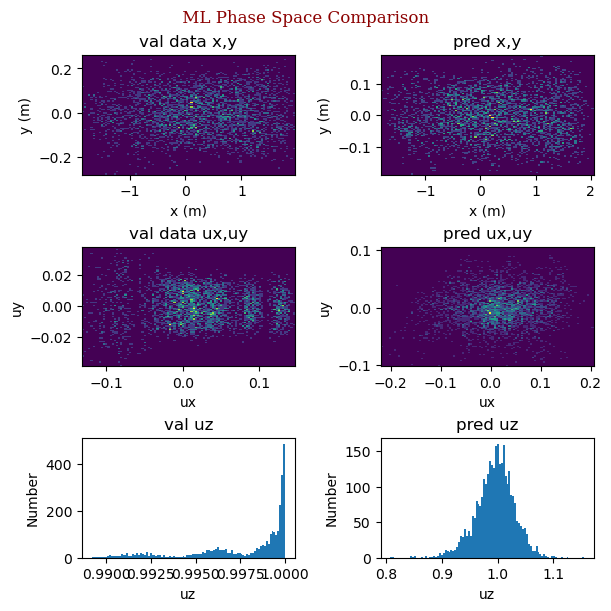

In [24]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
print(output_val_RNN)

unpack_output_val = output_val_RNN
part_num = len(part_lost_pred)
pred_survive_index = []
val_survive_index = []
same_survive_thresh
for i in range(0,part_num):
    if part_lost_pred[i]>same_survive_thresh:
        pred_survive_index.append(i)
    if output_lost_val_RNN[i]>same_survive_thresh:
        val_survive_index.append(i)
    
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[pred_survive_index]

print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,3], phase_space_pred_survive[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('uz')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(phase_space_pred_survive[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [25]:
#=================================================================================
#Advanced architecture with delta value as data instead of raw values
#=================================================================================

In [26]:
#get only the phase space from input df columns for delta phase space calculation


input_phase_space_for_delta_calc_df = output_df_lst[-2][fixfield_phase_space_headers]
input_phase_space_for_delta_calc_np_lst = input_phase_space_for_delta_calc_df.to_numpy()

output_np_lst = output_df_lst[-1][fixfield_phase_space_headers].to_numpy()
output_lost_lst = np.ones(len(output_df_lst[-1]["x [m]"])) #list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

print("number of particles : "+str(len(output_df_lst[-1]["x [m]"])))

#============================================================================================================
#put the read data into np array


input_delta_calc_train = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #input phase space for training data delta
output_delta_train = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #change of phase space instead of raw val

input_delta_calc_val = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #input phase space for val data delta
output_delta_val = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #change of phase space instead of raw val

#normalization will be done by tensorflow by tf.keras.layers.BatchNormalization()

lost_count_train = 0
lost_count_val = 0
for i in range(0,sample_part_num):
    input_delta_calc_train[i] = input_phase_space_for_delta_calc_np_lst[2*i]
    input_delta_calc_val[i] = input_phase_space_for_delta_calc_np_lst[2*i+1]

    if (output_train_RNN[i][3]+output_train_RNN[i][4]+output_train_RNN[i][5])<1e-6:#lost particles have 0 phase space val. So sum of ux,uy,uz is 0 -> lost
        output_delta_train[i] = output_np_lst[2*i] #don't calc delta for lost particle
        lost_count_train = lost_count_train + 1
    else:
        output_delta_train[i] = output_np_lst[2*i] - input_delta_calc_train[i] #calc delta for surviving particle

    if (output_val_RNN[i][3]+output_val_RNN[i][4]+output_val_RNN[i][5])<1e-6:
        output_delta_val[i] = output_np_lst[2*i+1]
        lost_count_val = lost_count_val + 1
    else:
        output_delta_val[i] = output_np_lst[2*i+1] - input_delta_calc_val[i]



print("output_delta_train")
print(output_delta_train)
print("lost_count_train : "+str(lost_count_train)+", lost_count_val : "+str(lost_count_val))
print(output_delta_val[4])
print("train particle num : "+str(len(input_train_RNN))+", val particle num : "+str(len(input_val_RNN))
      +", input column : "+str(len(input_train_RNN[0]))+",  output column : "+str(len(output_train_RNN[0])))

number of particles : 46875
output_delta_train
[[-1.49219275e+00  0.00000000e+00 -2.31880700e-02 -9.75537300e-02
  -5.81110000e-03 -1.52984490e-02]
 [-1.28096784e+00  0.00000000e+00  1.43523792e-01 -9.98338319e-02
  -5.15640000e-03  1.76412810e-02]
 [-1.38167880e+00  0.00000000e+00 -1.13717540e-01 -5.56650700e-02
  -3.41150000e-03 -7.53630000e-04]
 ...
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]]
lost_count_train : 20271, lost_count_val : 20261
[0. 0. 0. 0. 0. 0.]
train particle num : 23437, val particle num : 23437, input column : 2,  output column : 6


In [27]:
fixfield_part_info_input = tf.keras.Input(shape=(input_part_info_col_num,),name="fixfield_part_info_input")

fixfield_phase_space_input = tf.keras.Input(shape=(None, input_phase_space_col_num),name="fixfield_phase_space_input")

FFA_parameters = tf.keras.Input(shape=(None, FFA_parameter_len),name="ffa_parameters")

#part_info = tf.keras.layers.BatchNormalization()(fixfield_part_info_input)
part_info = tf.keras.layers.LayerNormalization()(fixfield_part_info_input)
part_info = tf.keras.layers.Dense(64, activation="tanh")(part_info)# phase space input
part_info = tf.keras.layers.Dense(64)(part_info)

#phase_space = tf.keras.layers.BatchNormalization()(fixfield_phase_space_input)
phase_space = tf.keras.layers.LayerNormalization()(fixfield_phase_space_input)
phase_space = tf.keras.layers.Dense(64, activation="tanh")(phase_space)
phase_space = tf.keras.layers.Dense(64)(phase_space)

#FFA_para = tf.keras.layers.BatchNormalization()(FFA_parameters)
FFA_para = tf.keras.layers.LayerNormalization()(FFA_parameters)
FFA_para = tf.keras.layers.Dense(64, activation="tanh")(FFA_para)
FFA_para = tf.keras.layers.Dense(64)(FFA_para)

combined_RNN = tf.keras.layers.Concatenate()([phase_space, FFA_para])
combined_RNN = tf.keras.layers.SimpleRNN(64, return_sequences=True)(combined_RNN)#, input_shape=[None, input_col_num]
combined_RNN = tf.keras.layers.SimpleRNN(64)(combined_RNN)

combined_all = tf.keras.layers.Concatenate()([combined_RNN, part_info])
combined_all = tf.keras.layers.Dense(128, activation="tanh")(combined_all)

phase_space_delta_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_delta_output")(combined_all)# phase space output
survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(combined_all)# Binary classification

model_RNN_sep_in_out_delta_calc = tf.keras.models.Model(
    inputs=[fixfield_part_info_input, fixfield_phase_space_input, FFA_parameters],
    outputs=[phase_space_delta_output,survival_output]
)

In [28]:
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  Huber()  KLDivergence  Poisson

model_RNN_sep_in_out_delta_calc.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss={
        "phase_space_delta_output": tf.keras.losses.Huber(),
        "survival_output": tf.keras.losses.BinaryCrossentropy()
    },

    loss_weights={
        "phase_space_delta_output": 1.0,
        "survival_output": 0.3
    },

    weighted_metrics={
        "phase_space_delta_output": ["accuracy"],#mae
        "survival_output": ["accuracy"]
    }
)

model_RNN_sep_in_out_delta_calc.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 fixfield_phase_space_input (In  [(None, None, 6)]   0           []                               
 putLayer)                                                                                        
                                                                                                  
 ffa_parameters (InputLayer)    [(None, None, 17)]   0           []                               
                                                                                                  
 layer_normalization_1 (LayerNo  (None, None, 6)     12          ['fixfield_phase_space_input[0][0
 rmalization)                                                    ]']                              
                                                                                            

In [29]:
#train the model
num_epochs = 2500
#Not worried about memory or local minima
batchSize = len(input_train_RNN)

#Train on data
history = model_RNN_sep_in_out_delta_calc.fit(
    x={
        "fixfield_part_info_input": input_part_info_train_RNN,
        "fixfield_phase_space_input": input_phase_space_train_RNN,
        "ffa_parameters": input_FFA_para_train_RNN
    },

    y={
        "phase_space_delta_output": output_delta_train,
        "survival_output": output_lost_train_RNN
    },

    sample_weight={
        "phase_space_delta_output": output_lost_train_RNN,
        "survival_output": np.ones(sample_part_num)
    },

    validation_data=({
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    },

    {
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val_RNN
    }#,

    #{"phase_space_output": output_lost_val,"survival_output": np.ones(sample_part_num)}#weight for validation data
    ),


    epochs=num_epochs,
    batch_size=batchSize
)

full_model_filename = 'model_RNN_sep_in_out_delta_calc'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model_RNN_sep_in_out_delta_calc.save(model_filename)

Epoch 1/2500
1/1 [==============================] - 3s 3s/step - loss: 0.2579 - phase_space_delta_output_loss: 0.0276 - survival_output_loss: 0.7675 - phase_space_delta_output_accuracy: 0.0278 - survival_output_accuracy: 0.1351 - val_loss: 0.2078 - val_phase_space_delta_output_loss: 0.0690 - val_survival_output_loss: 0.4629 - val_phase_space_delta_output_accuracy: 0.0046 - val_survival_output_accuracy: 0.8645
Epoch 2/2500
1/1 [==============================] - 0s 105ms/step - loss: 0.1572 - phase_space_delta_output_loss: 0.0184 - survival_output_loss: 0.4629 - phase_space_delta_output_accuracy: 0.0294 - survival_output_accuracy: 0.8649 - val_loss: 0.1663 - val_phase_space_delta_output_loss: 0.0495 - val_survival_output_loss: 0.3893 - val_phase_space_delta_output_accuracy: 0.0125 - val_survival_output_accuracy: 0.8645
Epoch 3/2500
1/1 [==============================] - 0s 101ms/step - loss: 0.1314 - phase_space_delta_output_loss: 0.0148 - survival_output_loss: 0.3888 - phase_space_delta

733/733 - 3s - loss: 0.0358 - phase_space_delta_output_loss: 4.0261e-04 - survival_output_loss: 0.1178 - phase_space_delta_output_accuracy: 0.8410 - survival_output_accuracy: 0.9483 - 3s/epoch - 5ms/step


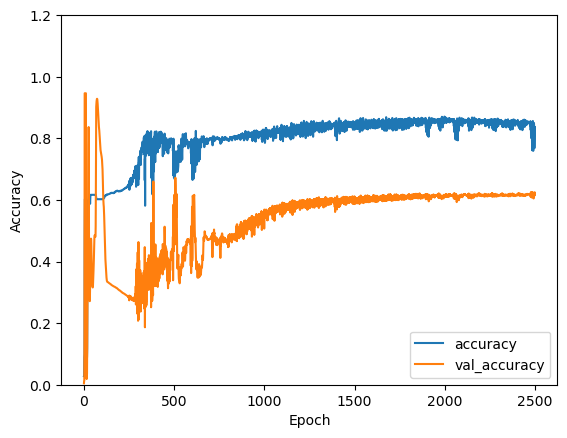

In [30]:
plt.plot(history.history['phase_space_delta_output_accuracy'], label='accuracy')
plt.plot(history.history['val_phase_space_delta_output_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')


    
#val_loss_phase_space, val_loss_lost_part, val_acc_phase_space,  val_acc_lost_part
results = model_RNN_sep_in_out_delta_calc.evaluate(x={
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    },
    y={
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val_RNN
    },
   sample_weight={
        "phase_space_delta_output": output_lost_val_RNN,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

733/733 - 3s - loss: 0.0358 - phase_space_delta_output_loss: 4.0261e-04 - survival_output_loss: 0.1178 - phase_space_delta_output_accuracy: 0.8410 - survival_output_accuracy: 0.9483 - 3s/epoch - 4ms/step


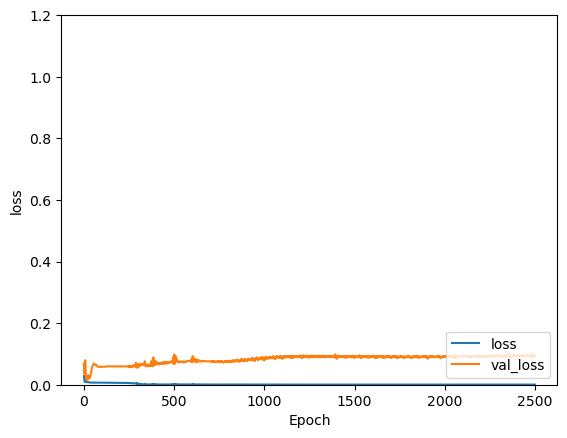

In [31]:
plt.plot(history.history['phase_space_delta_output_loss'], label='loss')
plt.plot(history.history['val_phase_space_delta_output_loss'], label = 'val_loss')
lost_ratio_lst = []
for i in range(0,len(history.history['phase_space_delta_output_loss'])):
    lost_ratio = history.history['val_phase_space_delta_output_loss'][i]/history.history['phase_space_delta_output_loss'][i]
    lost_ratio_lst.append(lost_ratio)

#plt.plot(lost_ratio_lst, label = 'val_loss/loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

results = model_RNN_sep_in_out_delta_calc.evaluate(x={
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    },
    y={
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val_RNN
    },
   sample_weight={
        "phase_space_delta_output": output_lost_val_RNN,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

In [32]:
output_sep_in_out_delta_calc_prediction = model_RNN_sep_in_out_delta_calc.predict({
        "fixfield_part_info_input": input_part_info_val_RNN,
        "fixfield_phase_space_input": input_phase_space_val_RNN,
        "ffa_parameters": input_FFA_para_val_RNN
    })

phase_space_pred = output_sep_in_out_delta_calc_prediction[0]
part_lost_pred = output_sep_in_out_delta_calc_prediction[1].squeeze()
for i in range(0, len(output_prediction)):
    phase_space_pred[i] = phase_space_pred[i] + input_delta_calc_val[i]
    #a = 0

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_sep_in_out_delta_calc_RNN_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

733/733 [==============================] - 2s 3ms/step
writing to file : ML_FFA_sample/FFA_ML_sep_in_out_delta_calc_RNN_result.dat


pred data
[2.5713118e-04 5.0227513e-06 2.3723573e-04 3.6144069e-05 4.4912736e-06
 2.9098919e-06 1.4095021e-05 7.3002284e-06 3.1647196e-05 8.1708757e-05
 6.4105038e-06 5.6797904e-05 8.9452988e-06 6.2052684e-05 6.9984173e-07
 7.6314547e-07 1.5494954e-06 3.3231590e-05 2.8669322e-06 1.6436381e-06
 1.5858042e-05 1.0552104e-06 1.7588898e-05 9.4701436e-06 6.7182959e-06
 3.1650800e-06 5.9496556e-06 3.9748970e-06 2.1244548e-05 1.8611503e-06]
val data
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
Within 23437 particles 13.551222426078425 % survival rate
Threshold value to have correct survival rate : 0.4173574841542436 est_sruvive_rate 0.13551222426078424
correct survival rate at same_survive : 0.7962844891509001 lost rate 0.9680722461430423


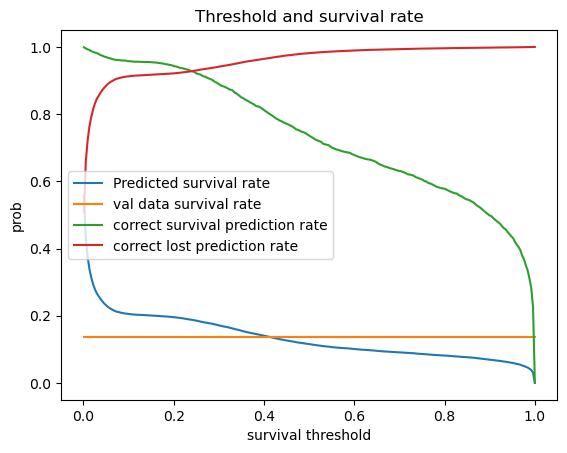

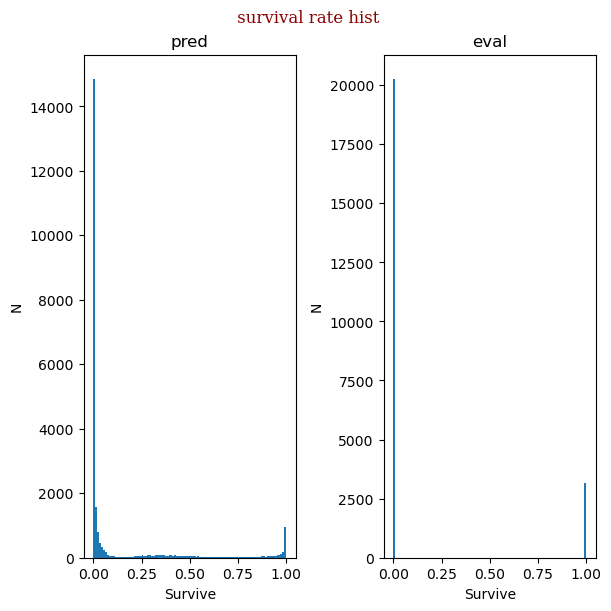

In [33]:
start_index = 270
end_index = 300
print("pred data")
print(part_lost_pred[start_index:end_index])
print("val data")
print(output_lost_val_RNN[start_index:end_index])

#calc total survival prob
thresh_num = 250
survive_thresh_lst = np.linspace(0.001,0.99999,thresh_num)
pred_prob_lst = np.zeros(thresh_num)
val_prob_lst = np.zeros(thresh_num)
correct_sur_prob_lst = np.zeros(thresh_num)
correct_lost_prob_lst = np.zeros(thresh_num)

for thresh_index in range(0, thresh_num):
    survive_thresh = survive_thresh_lst[thresh_index]
    pred_prob = 0
    val_prob = 0
    correct_sur_prob = 0
    correct_lost_prob = 0
    part_num = len(part_lost_pred)
    for i in range(0, part_num):
        if part_lost_pred[i]>survive_thresh:
            pred_prob = pred_prob + 1
    
        if output_lost_val_RNN[i]>survive_thresh:
            val_prob = val_prob + 1
            if part_lost_pred[i]>survive_thresh:
                correct_sur_prob = correct_sur_prob + 1 #add when both val data and pred is surviving
        else:
            if part_lost_pred[i]<survive_thresh:
                correct_lost_prob = correct_lost_prob + 1 #add when both val data and pred is lost
    
    correct_sur_prob = correct_sur_prob/val_prob #devide by val data surviving particle number
    correct_lost_prob = correct_lost_prob/(part_num-val_prob) #devide by val data lost particle number
    pred_prob = pred_prob/part_num
    val_prob = val_prob/part_num

    correct_sur_prob_lst[thresh_index] = correct_sur_prob
    correct_lost_prob_lst[thresh_index] = correct_lost_prob
    pred_prob_lst[thresh_index] = pred_prob
    val_prob_lst[thresh_index] = val_prob

    #print("Threshold value for survival : "+str(survive_thresh))
    #print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate and "+str(pred_prob*100)+" % survival rate from prediction")
    #print(str(correct_sur_prob*100)+" % correct survival prediction and "+str(correct_lost_prob*100)+" % correct lost prediction")


same_survive_thresh, est_sruvive_rate = find_intercept(survive_thresh_lst, val_prob_lst, survive_thresh_lst, pred_prob_lst)
#same_survive_thresh=0.965

print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate")
print("Threshold value to have correct survival rate : "+str(same_survive_thresh)+" est_sruvive_rate "+str(est_sruvive_rate))

f_correct_sur_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_sur_prob_lst, kind='linear')
f_correct_lost_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_lost_prob_lst, kind='linear')
correct_sur_prob_same_survive_thresh = f_correct_sur_prob(same_survive_thresh)
correct_lost_prob_same_survive_thresh = f_correct_lost_prob(same_survive_thresh)

print("correct survival rate at same_survive : "+str(correct_sur_prob_same_survive_thresh)+" lost rate "+str(correct_lost_prob_same_survive_thresh))

plt.title('Threshold and survival rate')
plt.plot(survive_thresh_lst, pred_prob_lst, label='Predicted survival rate')
plt.plot(survive_thresh_lst, val_prob_lst, label='val data survival rate')
plt.plot(survive_thresh_lst, correct_sur_prob_lst, label='correct survival prediction rate')
plt.plot(survive_thresh_lst, correct_lost_prob_lst, label='correct lost prediction rate')

plt.xlabel("survival threshold")
plt.ylabel("prob")
plt.legend()
plt.show()

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " survival rate hist"

fig.suptitle(Ttl, fontdict=font)

axs[0].set_title('pred')
axs[0].hist(part_lost_pred, 100)
axs[0].set_xlabel('Survive')
axs[0].set_ylabel('N')


axs[1].set_title('eval')
axs[1].hist(output_lost_val_RNN, 100)
axs[1].set_xlabel('Survive')
axs[1].set_ylabel('N')

plt.show()


23437
pred data
[[-1.5199717   0.02326787  0.04416992 -0.07168335  0.9231075  -0.02527616]
 [-1.5257672  -0.02616587 -0.08211117 -0.08373137  1.0198947  -0.01794844]
 [-1.2696065  -0.0348162   0.07224342 -0.09064113  1.0279491   0.06193226]
 ...
 [-0.03877831 -0.02022501  0.02766768  0.06541484  0.9994005  -0.02681271]
 [ 0.04401356 -0.00169914  0.00909064  0.07983663  1.0034039  -0.02025595]
 [ 0.01271799  0.0652428  -0.01164746  0.07840813  0.94764405 -0.05635902]]
val data
[[-1.383964    0.          0.04965096 -0.1010709   0.9948715   0.00391276]
 [-1.4321      0.         -0.09819983 -0.09356459  0.9955038  -0.01476015]
 [-1.120373    0.          0.01231477 -0.0958046   0.9950476   0.02648986]
 ...
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.        ]]
val surving particle num : 3176, pred surving particle num : 31

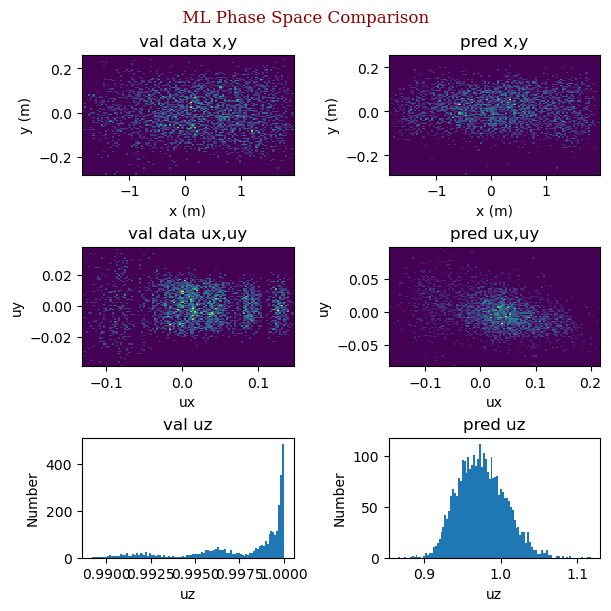

In [34]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
print(output_val_RNN)

unpack_output_val = output_val_RNN
part_num = len(part_lost_pred)
pred_survive_index = []
val_survive_index = []
same_survive_thresh
for i in range(0,part_num):
    if part_lost_pred[i]>same_survive_thresh:
        pred_survive_index.append(i)
    if output_lost_val_RNN[i]>same_survive_thresh:
        val_survive_index.append(i)
    
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[pred_survive_index]

print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,3], phase_space_pred_survive[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('uz')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(phase_space_pred_survive[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [35]:
#=================================================================================
#Advanced architecture with delta values as data instead of calculating delta from just final and initial step
#above delta = output-input, now delta0 = output0-input, delta1 = output1-output1 and have [delta0, delta1] as output from model
#=================================================================================

In [36]:
#get list of delta values of outputs


output_delta_seq_train_RNN = np.zeros(sample_part_num*FFA_num*output_col_num).reshape((sample_part_num,FFA_num,output_col_num)) #change of phase space instead of raw val
output_lost_train_seq_RNN = np.ones(sample_part_num*FFA_num).reshape((sample_part_num,FFA_num))#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

output_delta_seq_val_RNN = np.zeros(sample_part_num*FFA_num*output_col_num).reshape((sample_part_num,FFA_num,output_col_num)) #change of phase space instead of raw val
output_lost_seq_val_RNN = np.ones(sample_part_num*FFA_num).reshape((sample_part_num,FFA_num))#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

#normalization will be done by tensorflow by tf.keras.layers.BatchNormalization()

lost_count_seq_train = [0,0]
lost_count_seq_val = [0,0]
for i in range(0,sample_part_num):
    for j in range(0,FFA_num):
        if j==0:
            output_delta_seq_train_RNN[i][j] = output_phase_space_np_lst[j][2*i]-input_phase_space_np_lst[2*i]
            output_delta_seq_val_RNN[i][j] = output_phase_space_np_lst[j][2*i+1]-input_phase_space_np_lst[2*i+1]

        else:
            output_delta_seq_train_RNN[i][j] = output_phase_space_np_lst[j][2*i]-output_phase_space_np_lst[j-1][2*i]
            output_delta_seq_val_RNN[i][j] = output_phase_space_np_lst[j][2*i+1]-output_phase_space_np_lst[j-1][2*i+1]
    
        if (output_phase_space_np_lst[j][2*i][3]+output_phase_space_np_lst[j][2*i][4]+output_phase_space_np_lst[j][2*i][5])<1e-6:#lost particles have 0 phase space val. So sum of ux,uy,uz is 0 -> lost
            output_lost_train_seq_RNN[i][j] = 0 #record lost particle
            lost_count_seq_train[j] = lost_count_seq_train[j] + 1
    
        if (output_phase_space_np_lst[j][2*i+1][3]+output_phase_space_np_lst[j][2*i+1][4]+output_phase_space_np_lst[j][2*i+1][5])<1e-6:
            output_lost_seq_val_RNN[i][j] = 0 #record lost particle
            lost_count_seq_val[j] = lost_count_seq_val[j] + 1



print("output_delta_seq_train_RNN")
print(output_delta_seq_train_RNN)
print("lost_count_seq_train : "+str(lost_count_seq_train)+", lost_count_seq_val : "+str(lost_count_seq_val))
print(output_delta_seq_val_RNN[4])
print("train particle num : "+str(len(input_train_RNN))+", val particle num : "+str(len(input_val_RNN))
      +", input column : "+str(len(input_train_RNN[0]))+",  output column : "+str(len(output_delta_seq_train_RNN[0])))

output_delta_seq_train_RNN
[[[-3.50079380e-02  0.00000000e+00  7.23385344e-02 -1.62173964e-02
   -9.79741275e-06 -3.55014401e-03]
  [-1.49219275e+00  0.00000000e+00 -2.31880700e-02 -9.75537300e-02
   -5.81110000e-03 -1.52984490e-02]]

 [[ 2.11188417e-02  0.00000000e+00 -3.84740786e-03  6.46058340e-04
    3.64439322e-06  1.10184654e-02]
  [-1.28096784e+00  0.00000000e+00  1.43523792e-01 -9.98338319e-02
   -5.15640000e-03  1.76412810e-02]]

 [[-4.38721918e-01  0.00000000e+00 -5.24473849e-02 -2.55835859e-02
   -5.76560228e-04 -1.03938518e-02]
  [-1.38167880e+00  0.00000000e+00 -1.13717540e-01 -5.56650700e-02
   -3.41150000e-03 -7.53630000e-04]]

 ...

 [[-1.19764948e-01  0.00000000e+00  1.99929519e-01  5.71118112e-03
   -9.99979078e-01 -3.03726715e-03]
  [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
    0.00000000e+00  0.00000000e+00]]

 [[-2.52569611e-02  0.00000000e+00 -1.73543780e-01 -5.25056177e-03
   -9.99919799e-01  1.15250300e-02]
  [ 0.00000000e+00  0.00000000e+

In [37]:
fixfield_part_info_input = tf.keras.Input(shape=(input_part_info_col_num,),name="fixfield_part_info_input")

fixfield_phase_space_input = tf.keras.Input(shape=(None, input_phase_space_col_num),name="fixfield_phase_space_input")

FFA_parameters = tf.keras.Input(shape=(None, FFA_parameter_len),name="ffa_parameters")

#part_info = tf.keras.layers.BatchNormalization()(fixfield_part_info_input)
part_info = tf.keras.layers.LayerNormalization()(fixfield_part_info_input)
part_info = tf.keras.layers.Dense(64, activation="tanh")(part_info)# phase space input
part_info = tf.keras.layers.Dense(64)(part_info)

#phase_space = tf.keras.layers.BatchNormalization()(fixfield_phase_space_input)
phase_space = tf.keras.layers.LayerNormalization()(fixfield_phase_space_input)
phase_space = tf.keras.layers.Dense(64, activation="tanh")(phase_space)
phase_space = tf.keras.layers.Dense(64)(phase_space)

#FFA_para = tf.keras.layers.BatchNormalization()(FFA_parameters)
FFA_para = tf.keras.layers.LayerNormalization()(FFA_parameters)
FFA_para = tf.keras.layers.Dense(64, activation="tanh")(FFA_para)
FFA_para = tf.keras.layers.Dense(64)(FFA_para)

combined_RNN = tf.keras.layers.Concatenate()([phase_space, FFA_para])
combined_RNN = tf.keras.layers.SimpleRNN(64, return_sequences=True)(combined_RNN)#, input_shape=[None, input_col_num]
combined_RNN = tf.keras.layers.SimpleRNN(64, return_sequences=True)(combined_RNN)#return_sequences=True to get output delta from every step

combined_all = tf.keras.layers.Concatenate()([combined_RNN, part_info])
combined_all = tf.keras.layers.Dense(128, activation="tanh")(combined_all)

phase_space_delta_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_delta_output")(combined_all)# phase space output
survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(combined_all)# Binary classification

model_RNN_sep_in_out_delta_calc = tf.keras.models.Model(
    inputs=[fixfield_part_info_input, fixfield_phase_space_input, FFA_parameters],
    outputs=[phase_space_delta_output,survival_output]
)

ValueError: A `Concatenate` layer requires inputs with matching shapes except for the concatenation axis. Received: input_shape=[(None, None, 64), (None, 64)]